# Assignment 3 — Probability for Pattern Recognition
**ENGS 3302 Pattern Recognition · Week 3** · Submit this notebook (`.ipynb`) on Moodle **with all cells run**
(*Runtime → Restart and run all*, then *File → Download → .ipynb*).

**How it is marked (about 1% of the course):**
**1** = the notebook runs, every task has a real attempt, and every *explain in your own words* question is answered ·
**0.5** = more than half of the tasks are attempted · **0** = not submitted, empty, or copied.
In the in-person sessions you may be asked to explain part of your work for two minutes; if you cannot explain it, the mark is 0.
Late work: accepted up to 48 hours after the deadline without penalty, not after.

In [1]:
# Run this cell first. It loads the libraries, a helper that checks your answers, and the penguin data.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

def check(label, got, expected, tol=1e-2):
    """Prints a green tick if `got` is close to `expected`, otherwise a red cross."""
    try:
        if isinstance(expected, str):
            ok = str(got) == expected
        else:
            ok = got is not None and np.allclose(np.asarray(got, dtype=float),
                                                 np.asarray(expected, dtype=float), atol=tol)
    except Exception:
        ok = False
    print(f"✅ {label}" if ok else f"❌ {label}: expected {expected}, got {got}")

# Palmer Penguins (Horst, Hill & Gorman 2020, CC0): 344 penguins of 3 species, measured in mm and g.
# Uses penguins.csv from the Moodle zip if it is next to the notebook, otherwise downloads it.
PENGUIN_FEATURES = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
def load_penguins():
    """Returns the cleaned table: 342 penguins with all four measurements."""
    try:
        df = pd.read_csv("penguins.csv")
    except FileNotFoundError:
        df = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv")
    return df.dropna(subset=PENGUIN_FEATURES).reset_index(drop=True)   # 2 penguins have no measurements

peng = load_penguins()
print("Ready.", len(peng), "penguins")

Ready. 342 penguins


### Task 1 — A coin that is not fair
A coin shows heads with probability 0.3. With `rng = np.random.default_rng(3)`, simulate **20** tosses and then **20 000** tosses
(`rng.random(n) < 0.3` is one toss per value). Print the fraction of heads for each.

In [2]:
rng = np.random.default_rng(3)
for n in (20, 20000):
    tosses = rng.random(n) < 0.3
    print(f"{n:6d} tosses: fraction of heads = {np.mean(tosses):.4f}")

    20 tosses: fraction of heads = 0.3500
 20000 tosses: fraction of heads = 0.2992


**Explain in your own words (2–3 sentences):** Why is the fraction after 20 tosses further from 0.3 than the fraction after 20 000 tosses?
What does this tell you about estimating a probability from a small data set?

*Your answer:* After 20 tosses, random variation has a bigger effect on the results, so the fraction may be far from 0.3. After 20,000 tosses, the fraction is usually closer to 0.3 because we have more data. This tells us that a small data set may not give an accurate estimate of the true probability.
**In other words**, the greater the number of trials, the more accurate our estimate of the true probability becomes.

### Task 2 — When the catch changes
Use the catch table of the Notes: $P(\text{light}\mid\text{sea bass})=56/60$ and $P(\text{light}\mid\text{salmon})=3/40$.
Compute $P(\text{sea bass}\mid\text{light})$ when **10%** of the catch is sea bass. Show the total probability $P(\text{light})$ too.

In [3]:
catch = pd.DataFrame({
    "species": ["sea bass"] * 60 + ["salmon"] * 40,
    "look": ["light"] * 56 + ["dark"] * 4 + ["light"] * 3 + ["dark"] * 37
})

table = pd.crosstab(catch["species"], catch["look"], margins=True)
print(table, "\n")

# Given probabilities
p_light_given_bass = 56 / 60
p_light_given_salmon = 3 / 40

# 10% sea bass and 90% salmon
p_bass = 0.10
p_salmon = 0.90

# Total probability
p_light = p_light_given_bass * p_bass + p_light_given_salmon * p_salmon

# Bayes' rule
p_bass_given_light = (p_light_given_bass * p_bass) / p_light

print("P(light) =", round(p_light, 4))
print("P(sea bass | light) =", round(p_bass_given_light, 4))

look      dark  light  All
species                   
salmon      37      3   40
sea bass     4     56   60
All         41     59  100 

P(light) = 0.1608
P(sea bass | light) = 0.5803


**Explain in your own words (2–3 sentences):** The fish look exactly the same as in the Notes, but the answer is now 0.58 instead of 0.949.
Why did it change?

*Your answer:* The answer changed because the prior probability of sea bass decreased from 60% to 10%. Even though the fish look exactly the same, sea bass are now much less common in the catch. This shows that the probability depends on both the fish's appearance and how common each species is.

### Task 3 — A density histogram by hand
Take the **Chinstrap bill length** (`bill_length_mm`). With bins of width 2 mm from 40 to 58 (`np.arange(40, 60, 2)`), compute the counts with
`np.histogram`, then the density heights. Print the height of the tallest bar, the fraction of penguins in it, and check that the total area is 1.

counts:  [ 1  5  8 13 10 21  7  2  1]
Tallest bar height = 0.1544
Fraction in tallest bar = 0.309
total area = 1.0


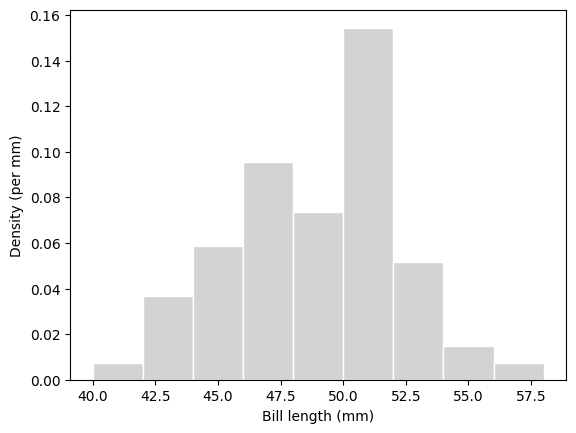

In [4]:

import matplotlib.pyplot as plt

# Select Chinstrap penguins
chin = peng[peng["species"] == "Chinstrap"]

# Get bill length
bill = chin["bill_length_mm"].dropna().to_numpy()

# Define bins (width = 2 mm)
edges = np.arange(40, 60, 2)

# Calculate counts
counts, _ = np.histogram(bill, edges)

# Calculate density
density = counts / (len(bill) * 2)

# Find tallest bar
tallest = np.argmax(density)

print("counts: ", counts)

print("Tallest bar height =", round(density[tallest], 4))

print("Fraction in tallest bar =", round(counts[tallest] / len(bill), 3))

print("total area =", np.sum(density * 2))

# Plot histogram
plt.hist(bill, bins=edges, density=True,
         color="lightgray", edgecolor="white")

plt.xlabel("Bill length (mm)")
plt.ylabel("Density (per mm)")
plt.show()

### Task 4 — Is the normal model good for Adelie body mass?

*   List item
*   List item


Fit a normal curve to the **Adelie** `body_mass_g` (mean and `std(ddof=0)`). Body mass is recorded in steps of 25 g, so the masses 3500 to 4000 g
stand for the interval 3487.5 to 4012.5 g. Compute the model probability of that interval and the real fraction of Adelie penguins with 3500 to 4000 g. Plot the density histogram with the curve on top.

Adelie  n=151  mean=3700.66  sd=457.05


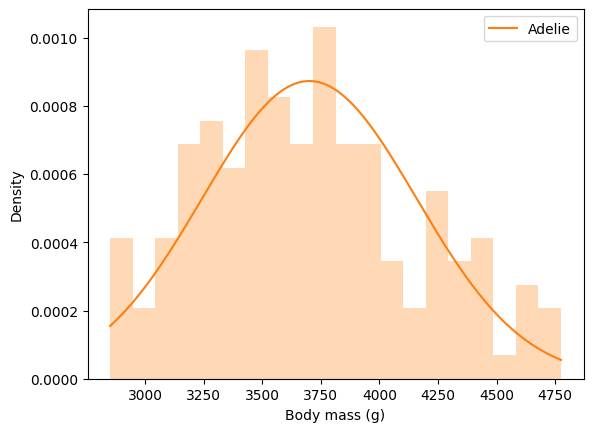

Adelie, 3500 to 4000 g:  normal model 0.432   real fraction 0.411


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Adelie body mass
v = peng.loc[peng["species"] == "Adelie", "body_mass_g"].dropna()

# Mean and standard deviation
print(f"Adelie  n={len(v):3d}  mean={v.mean():.2f}  sd={v.std(ddof=0):.2f}")

# Plot histogram
plt.hist(v, bins=20, density=True, alpha=0.3,
         color="tab:orange")

# Plot normal curve
xs = np.linspace(v.min(), v.max(), 300)
plt.plot(xs, norm.pdf(xs, v.mean(), v.std(ddof=0)),
         color="tab:orange", label="Adelie")

plt.legend()
plt.xlabel("Body mass (g)")
plt.ylabel("Density")
plt.show()

# Body mass is recorded in steps of 25 g.
# 3500 to 4000 g represents 3487.5 to 4012.5 g.

model = norm.cdf(4012.5, v.mean(), v.std(ddof=0)) - norm.cdf(3487.5, v.mean(), v.std(ddof=0))

data = np.mean((v >= 3500) & (v <= 4000))

print(f"Adelie, 3500 to 4000 g:  normal model {model:.3f}   real fraction {data:.3f}")

**Explain in your own words (2–3 sentences):** Compare the two numbers and the picture. Is the normal curve a good model here? Compare with
the Gentoo flippers in the lab, where the model gave 0.579 and the data 0.602.

*Your answer:* The normal curve is a good model for Adelie body mass because the model probability (0.432) is close to the real fraction (0.411). The Gentoo flipper model is also good because its values (0.579 and 0.602) are close. Both models give good estimates of the real data.

### Task 5 — Probability or density?
**Explain in your own words (3–4 sentences):** A classmate computes `norm.pdf(205, 217.19, 6.46)` = 0.0104 and writes
*"the probability that a Gentoo penguin has a flipper of exactly 205 mm is 1%."* What is wrong? What is the probability of exactly 205 mm,
and how would you compute the probability of a flipper from 204.5 to 205.5 mm? Finally, explain why the same density in metres is 10.4, larger than 1.

*Your answer:* The classmate is wrong because norm.pdf() gives density, not probability. The probability of exactly 205 mm is zero for a continuous distribution. To calculate the probability between 204.5 and 205.5 mm, we subtract norm.cdf(204.5) from norm.cdf(205.5). Density depends on the unit of measurement, so it becomes 10.4 in metres, but the probability stays the same.